#### ROC Curve

ROC stands for Receiver Operating Characteristic.

An ROC curve shows how well a classification model can distinguish between two classes at different classification thresholds.

It uses two values:
- True Positive Rate (TPR): How many actual positive cases the model correctly identifies.
- False Positive Rate (FPR): How many actual negative cases the model incorrectly identifies as positive.

#### AUC
AUC stands for Area Under the Curve.

It measures how well the model distinguishes between positive and negative classes.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

In [3]:
# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [4]:
# Train model
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

In [5]:
# Get predicted probabilities for positive class
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc)

AUC Score: 0.9953703703703703


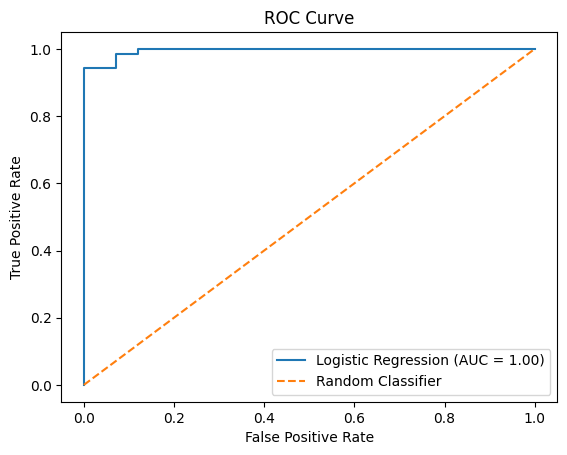

In [6]:
# Plot ROC curve
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.2f})")

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()